###Principal component analysis of the Yield curve

Reading material: Before addressing this exercise, it is recommended that is study

Principal Component Analysis of the Yield Curve chapter

Prepare the environment

In [1]:
from numpy import cumsum, linspace, size, sum, where, zeros
from numpy.linalg import eigh
from scipy.linalg import toeplitz
from seaborn import lineplot

# Task 1:

Write a script in which I, given multivariate vector of target variables X= (X1,...,Xn)'
(as represented by its own covariance matrix, verify thaat as the correkations among the target variables Xn,
increases, the minimum number k_bar of the principal-component factors Z^PC k necessary to cover a large r-squared
(say more than 95%) decreases.

To this purpose, restrict the computations to a target covariance with a special Toeplitz structure similar
to covariance of te yield curve increments.

More precisely follow the belo instructions

- Set the dimension of the target variable to n_bar = 500

In [2]:
n_bar = 500

- Define a grid vector of increasing correlations e^grid = (0,...,0.99)

This is the correlation grid - values 0, 0.01, 0.02,....0.99.
We build one covariance matrix per value.  the grid spacing matters.

In [3]:
rho_grid = linspace(0, 0.99, 100)
print(rho_grid)

[0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13
 0.14 0.15 0.16 0.17 0.18 0.19 0.2  0.21 0.22 0.23 0.24 0.25 0.26 0.27
 0.28 0.29 0.3  0.31 0.32 0.33 0.34 0.35 0.36 0.37 0.38 0.39 0.4  0.41
 0.42 0.43 0.44 0.45 0.46 0.47 0.48 0.49 0.5  0.51 0.52 0.53 0.54 0.55
 0.56 0.57 0.58 0.59 0.6  0.61 0.62 0.63 0.64 0.65 0.66 0.67 0.68 0.69
 0.7  0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.8  0.81 0.82 0.83
 0.84 0.85 0.86 0.87 0.88 0.89 0.9  0.91 0.92 0.93 0.94 0.95 0.96 0.97
 0.98 0.99]


For each E in E^grid

- Construct a symmetric Toeplitz matrix sigma^2,x of dimension n_nar having as first column a vector (1,...,E)
with equally spaced, decreasing entries;
- Perform PCA on sigma^2,x;
- Compute the vector r^2 = (r^2,1,....,r^2,n_bar) where r^2,n denotes the r-squared recovered by the first n
principal components;
- Find the minimum integer k_bar for which r^2,k > 95%

Hint use function toeplitz to compute the Toeplitz matrix sigma^2,x;

In [9]:
iteration = 0

k_bar = zeros(size(rho_grid))

for rho in rho_grid:
    # 1. Toeplitz matrix
    # linspace(...) -> makes the first column, 500 equally spaced values falling from 1 to ..
    # toeplitz (diagonal constant matrix) -> copies the column down every diagonal,
    # so each entry depends only on how far apart 2 variables are.  Like a yield curve/correlation matrix.
    # Every diagonal
    sigma2_x = toeplitz(linspace(1, rho, n_bar))
    # 2. PCA on sigma2_x
    # eigh -> numpy's eigen decomposition for symmetric matrices, returning eigenvalues (gamma) and eigenvectors (e)
    # [::-1] lines flip, so gamma is the largest,
    # eigenvectors 'e' are the principal variances
    lam, e = eigh(sigma2_x)
    lam = lam[::-1]
    e = e[:, ::-1]
    # 3. r-squared
    # cumsum gives all the running totals at once
    r2 = cumsum(lam) / sum(lam)
    # 4. minimum k_bar for r2 > 95%
    # where(r2 > 0.95)[0][0] + 1 -> gets the indices where r^2 exceeds 95%
    k_bar[iteration] = where(r2 > 0.95)[0][0] + 1
    iteration = iteration + 1

- Plot k_bar as a function of q.

In [10]:
lineplot(x=rho_grid, y=k_bar).set(xlabel='$\\varrho$', ylabel='$||bar{k}$')

[Text(0.5, 0, '$\\varrho$'), Text(0, 0.5, '$||bar{k}$')]

# Task 2.

Which is the minimum correlation value q*3 for which k_bar = 3 principal components recover 95% of total risk

rho_star_3 =  0.38


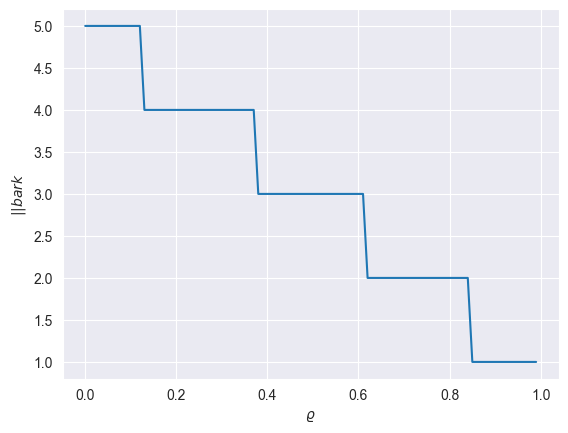

In [11]:
# minimum value rho for k_bar = 3 principal components recover 95% of total risk
rho_star_3 = rho_grid[where(k_bar == 3)[0][0]]

# This finds the first q on the grid where k_bar hits 3.

##################  results #####################
print('rho_star_3 = ', rho_star_3)